# Overview of Mislocalized Variants

In [2]:
import seaborn as sns
import numpy as np
import polars as pl
from tqdm import tqdm
import matplotlib.pyplot as plt
from pycytominer.feature_select import feature_select
from sklearn.neighbors import NearestNeighbors
from sklearn.decomposition import PCA
from sklearn.metrics.pairwise import cosine_distances
import networkx as nx
import community.community_louvain as community_louvain
from kneed import KneeLocator
import umap
import pandas as pd
from utils import inverse_normal_transform
# from adjustText import adjust_text
import igraph as ig
import leidenalg

sns.set_theme(style='white')

## 1. Loading Data

In [3]:
ref_var_cell_all_prof_df = pl.read_parquet("../1_snakemake_pipeline/2025_varchamp_snakemake/2.snakemake_pipeline/outputs/ref_var_gfp_feat_sc_cp_profiles_all.parquet")
feat_df = pl.read_csv("../../3_outputs/feat_importance_gt1e-3_all_alleles.csv")

In [4]:
imaging_summary_clinvar = pl.read_csv("../../3_outputs/imaging_analyses_summary_clinvar.tsv", separator="\t", infer_schema_length=100000)
imaging_summary_clinvar_hits = imaging_summary_clinvar.filter(
    pl.col("Altered_95th_perc_both_batches_GFP"),
)
misloc_alleles = imaging_summary_clinvar_hits["gene_allele"].to_list()

## Protein abundance change
imaging_summary_clinvar_abund_chg = imaging_summary_clinvar.filter(
    (pl.col("U2OS_prot_abun_t_stat").is_not_null()) & (pl.col("U2OS_prot_abun_t_pval") < 0.05/943)
)
prot_abund_chg_alleles = imaging_summary_clinvar_abund_chg["gene_allele"].to_list()

In [5]:
# ax = sns.regplot(
#     data=imaging_summary_clinvar.to_pandas(),
#     x="AUROC_Mean_GFP",
#     y="AUROC_Mean_GFP_ADJ"
# )
# ax.set_xlim(0.45, 1.05)
# ax.set_ylim(0.45, 1.05)
# plt.show()

# ax = sns.regplot(
#     data=imaging_summary_clinvar.filter(
#         (pl.col("AUROC_Mean_GFP")>.9) | (pl.col("AUROC_Mean_GFP_ADJ")>.9)
#     ).to_pandas(),
#     x="AUROC_Mean_GFP",
#     y="AUROC_Mean_GFP_ADJ"
# )
# ax.set_xlim(0.825, 1.005)
# ax.set_ylim(0.825, 1.005)
# plt.show()
imaging_summary_clinvar_hits

Gene,gene_allele,U2OS_cc_t_stat,U2OS_cc_t_pval,U2OS_prot_abun_t_stat,U2OS_prot_abun_t_orig_pval,U2OS_prot_abun_t_adj_pval,U2OS_prot_abun_t_pval,Metadata_Bio_Batch,Altered_95th_perc_both_batches_GFP_ADJ,Altered_95th_perc_both_batches_GFP,Altered_95th_perc_both_batches_DNA,Altered_95th_perc_both_batches_Mito,Altered_95th_perc_both_batches_AGP,Altered_95th_perc_both_batches_Morph,Altered_99th_perc_both_batches_GFP_ADJ,Altered_99th_perc_both_batches_GFP,Altered_99th_perc_both_batches_DNA,Altered_99th_perc_both_batches_Mito,Altered_99th_perc_both_batches_AGP,Altered_99th_perc_both_batches_Morph,AUROC_Mean_GFP_ADJ,AUROC_Mean_GFP,AUROC_Mean_DNA,AUROC_Mean_Mito,AUROC_Mean_AGP,AUROC_Mean_Morph,AUROC_BioRep1_Morph,AUROC_BioRep1_AGP,AUROC_BioRep1_Mito,AUROC_BioRep1_DNA,AUROC_BioRep1_GFP,AUROC_BioRep1_GFP_ADJ,AUROC_BioRep2_Morph,AUROC_BioRep2_AGP,AUROC_BioRep2_Mito,AUROC_BioRep2_DNA,…,g2p_Non-terminal residue (UniProt),g2p_O-GalNAc,g2p_O-GlcNAc,g2p_Peptide (UniProt),g2p_Phi angle (degrees)*,g2p_Phosphorylation,g2p_Pocket number (fpocket)*,g2p_Propeptide (UniProt),g2p_Psi angle (degrees)*,g2p_Region (UniProt),g2p_Regulatory sites,g2p_Repeat (UniProt),g2p_SNP-associated PTMs,g2p_SUMOylation,g2p_Secondary structure (DSSP 3-state)*,g2p_Secondary structure (DSSP 9-state)*,g2p_Secondary structure (PDBe/SIFTS),g2p_Sequence conflict (UniProt),g2p_Sequence uncertainty (UniProt),g2p_Signal (UniProt),g2p_Site (UniProt),g2p_Substrate genes,g2p_Topological domain (UniProt),g2p_Transit peptide (UniProt),g2p_Transmembrane (UniProt),g2p_Ubiquitination,g2p_Zinc finger (UniProt),plddt_f32,rsa_f32,pLDDT_Category,RSA_Category,OMIM_IDs,inheritance_pattern,inheritance_source,disease_modules,disease_module_count,OMIM_disease_names
str,str,f64,f64,f64,f64,f64,f64,str,bool,bool,bool,bool,bool,bool,bool,bool,bool,bool,bool,bool,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,…,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,f64,f64,str,str,str,str,str,str,i64,str
"""GFAP""","""GFAP_Asn77Ser""",0.602116,0.566081,9.583633,0.000028,0.000174,0.000174,"""2025_03_Batch_15-16""",true,true,false,false,false,false,false,false,false,false,false,false,0.978313,0.968469,0.585899,0.814176,0.867727,0.707895,0.613056,0.868296,0.737507,0.576605,0.960268,0.970341,0.802735,0.867159,0.890845,0.595192,…,"""""","""""","""""","""""","""-64.5""","""""","""Pocket 5: Mean pLDDT: 80.91, V…","""""","""-39.8""","""Coil 1A""","""""","""""","""dbSNP: rs58732244; Variant typ…","""""","""H (helix)""","""H (α-helix)""","""""","""""","""""","""""","""""","""""","""""","""""","""""","""""","""""",90.75,62.42038,""">90""","""10-90""","""203450""","""autosomal dominant""","""OMIM""","""Rare genetic eye disease; Rare…",2,"""ALEXANDER DISEASE"""
"""IL36RN""","""IL36RN_Leu27Pro""",5.322175,0.001097,-5.58134,0.000832,0.002186,0.002186,"""2025_03_Batch_15-16""",true,true,true,true,true,true,true,true,true,true,false,true,0.990293,0.996291,0.926636,0.983549,0.913593,0.96307,0.982761,0.925382,0.993874,0.973461,0.994517,0.985112,0.943378,0.901804,0.973223,0.879812,…,"""""","""""","""""","""""","""-109.3""","""""","""""","""""","""161.0""","""""","""""","""""","""""","""""","""B (undefined)""","""E (parallel sheets)""","""Beta strand""","""""","""""","""""","""""","""""","""""","""""","""""","""""","""""",97.31,7.9268293,""">90""","""<10""","""614204""","""autosomal recessive""","""OMIM""","""Rare genetic immune disease; R…",2,"""PSORIASIS 14, PUSTULAR"""
"""NR0B1""","""NR0B1_Asn440Ile""",-3.257613,0.01391,-13.250179,0.000003,0.000038,0.000038,"""2025_03_Batch_15-16""",true,true,false,false,false,false,true,true,false,false,false,false,0.998136,0.9914,0.481305,0.778369,0.690655,0.622407,0.787776,0.765525,0.832189,0.561267,0.988554,0.997037,0.457038,0.615784,0.724548,0.401343,…,"""""","""""","""""","""""","""-84.0""","""""","""""","""""","""131.3""","""""","""""","""""","""""","""""","""C (loop/coil)""","""C (loop/coil)""","""""","""""

In [6]:
# TOP_NUM_FEAT_MISLOC_VAR = 5
# # Get top 10 for each variant with feature names
# top_feat_misloc_alleles = []
# for col in misloc_alleles:
#     top_feats = feat_df.filter(
#         pl.col(col).is_in(pl.col(col).top_k(TOP_NUM_FEAT_MISLOC_VAR))
#     ).select(["cp_feature", col])
#     # print(top_feats.sort(col))
#     top_feat_misloc_alleles.append(top_feats)
    
# # Start with all features and left join each variant's top 10
# result_df = feat_df.select("cp_feature").unique().sort("cp_feature")
# for i, col in enumerate(misloc_alleles):
#     result_df = result_df.join(top_feat_misloc_alleles[i], on="cp_feature", how="left")

# misloc_var_top10_feat_df = result_df.select(
#     ["cp_feature"] + misloc_alleles
# ).filter(
#     ~pl.all_horizontal(pl.all().exclude("cp_feature").is_null())
# )
# get_top_n_feats_misloc_alleles = misloc_var_top10_feat_df["cp_feature"].to_list()
# len(get_top_n_feats_misloc_alleles)

misloc_var_sig_feat_df = feat_df.filter(
    # pl.col(col).is_in(pl.col(col).top_k(10))
    pl.max_horizontal(misloc_alleles) > .01
)
get_sig_feats_misloc_alleles = misloc_var_sig_feat_df["cp_feature"].to_list()

In [7]:
norm_vars_feat_df, norm_var_sc_feat_df = pl.DataFrame(), pl.DataFrame()
sig_diff_feat = [feat for feat in get_sig_feats_misloc_alleles if feat in ref_var_cell_all_prof_df.columns] #[feat for feat in get_top_feats if feat in ref_var_cell_all_prof_df.columns]

for gene in tqdm(imaging_summary_clinvar_hits["Gene"].unique().to_list()):
    gene_mean = ref_var_cell_all_prof_df.filter(pl.col("Metadata_gene_allele")==gene).select(sig_diff_feat).mean().to_numpy()[0].tolist()
    gene_std = ref_var_cell_all_prof_df.filter(pl.col("Metadata_gene_allele")==gene).select(sig_diff_feat).std().to_numpy()[0].tolist()

    # print(gene, np.mean(gene_mean), np.min(gene_std))
    z_norm_var_sc_feat_df = ref_var_cell_all_prof_df.filter(
        (pl.col("Metadata_gene_allele").str.starts_with(f"{gene}_"))
        &(pl.col("Metadata_gene_allele")!=gene)
        &(pl.col("Metadata_gene_allele").is_in(imaging_summary_clinvar_hits["gene_allele"].unique()))
    ).with_columns(
        [((pl.col(col) - pl.lit(gene_mean[i])) / pl.lit(gene_std[i])).alias(col)
        for i, col in enumerate(sig_diff_feat)]
    )
    norm_var_sc_feat_df = pl.concat([
        norm_var_sc_feat_df,
        z_norm_var_sc_feat_df
    ])
    z_norm_var_feat_df = z_norm_var_sc_feat_df.group_by(
        "Metadata_gene_allele", "Metadata_Plate", "Metadata_Well" ## aggregate by well first
    ).agg(
        pl.col(col).mean().alias(col)
        for col in sig_diff_feat
    ).group_by(
        "Metadata_gene_allele" ## aggregate by allele
    ).agg(
        pl.col(col).median().alias(col)
        for col in sig_diff_feat
    )#.to_pandas().set_index("Metadata_gene_allele")[sig_diff_feat]

    norm_vars_feat_df = pl.concat(
        [norm_vars_feat_df, z_norm_var_feat_df],
         how="diagonal"
    )

100%|██████████| 49/49 [00:13<00:00,  3.53it/s]


In [8]:
# Standardize the features before PCA
var_zscore_feat_gfp_filtered_int_df = inverse_normal_transform(norm_vars_feat_df)
## feature selection
var_zscore_feat_gfp_filtered_int_feat_sel_df = feature_select(
    var_zscore_feat_gfp_filtered_int_df.to_pandas(), operation="variance_threshold"
)
var_zscore_feat_gfp_filtered_int_feat_sel_df = pl.DataFrame(
    feature_select(var_zscore_feat_gfp_filtered_int_feat_sel_df, operation="correlation_threshold")
)
## Append important medadata to data frame
cols = [
    "gene_allele",
    "Metadata_Bio_Batch",
    "Altered_95th_perc_both_batches_GFP_ADJ",
    "AUROC_Mean_GFP_ADJ",
    "clinvar_OMIM_id",
    "OMIM_IDs",
    "OMIM_disease_names",
]
var_zscore_feat_gfp_filtered_int_feat_sel_df = var_zscore_feat_gfp_filtered_int_feat_sel_df.join(
    imaging_summary_clinvar.select(cols).rename(
        {k: f"Metadata_{k}" for k in cols if "Metadata" not in k}
    ),
    on="Metadata_gene_allele",
    how="inner"
)

  0%|          | 0/183 [00:00<?, ?it/s]

In [9]:
df_meta = var_zscore_feat_gfp_filtered_int_feat_sel_df.to_pandas().set_index("Metadata_gene_allele")
df = df_meta[[c for c in df_meta.columns if "Metadata_" not in c]]
df.shape

(145, 56)

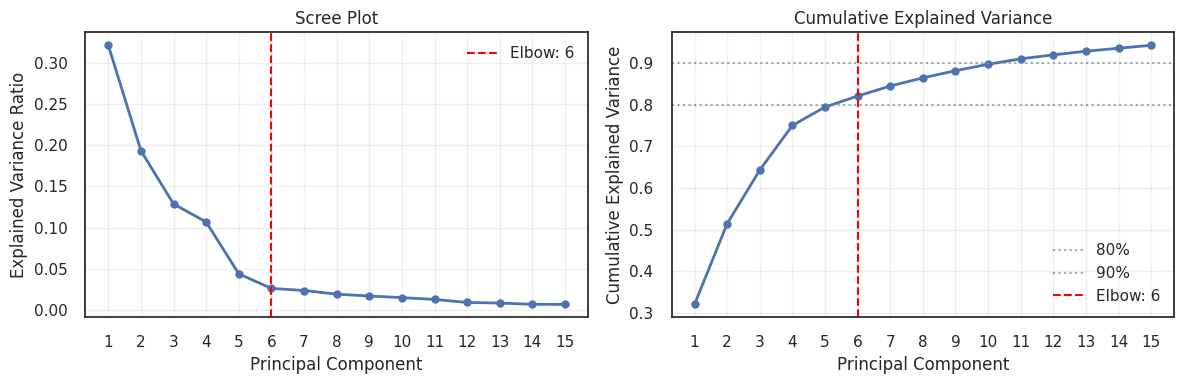

Optimal components: 6
Explained variance at elbow: 82.1%


In [10]:
# Perform PCA
pca = PCA()
pca_result = pca.fit_transform(df)

# Calculate variances
explained_variance_ratio = pca.explained_variance_ratio_
cumulative_variance = np.cumsum(explained_variance_ratio)

# Find elbow point using KneeLocator
knee_locator = KneeLocator(
    range(1, len(explained_variance_ratio)+1),
    explained_variance_ratio,
    curve='convex',
    direction='decreasing'
)
optimal_components = knee_locator.knee

# Plot results
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

# Scree plot
n_show = min(15, len(explained_variance_ratio))
ax1.plot(range(1, n_show + 1), explained_variance_ratio[:n_show], 'o-', linewidth=2)
ax1.axvline(x=optimal_components, color='red', linestyle='--', label=f'Elbow: {optimal_components}')
ax1.set_xlabel('Principal Component')
ax1.set_ylabel('Explained Variance Ratio')
ax1.set_title('Scree Plot')
ax1.set_xticks(range(1, n_show + 1))
ax1.legend()
ax1.grid(True, alpha=0.3)

# Cumulative variance plot
ax2.plot(range(1, n_show + 1), cumulative_variance[:n_show], 'o-', linewidth=2)
ax2.axhline(y=0.8, color='gray', linestyle=':', alpha=0.7, label='80%')
ax2.axhline(y=0.9, color='gray', linestyle=':', alpha=0.7, label='90%')
ax2.axvline(x=optimal_components, color='red', linestyle='--', label=f'Elbow: {optimal_components}')
ax2.set_xlabel('Principal Component')
ax2.set_ylabel('Cumulative Explained Variance')
ax2.set_title('Cumulative Explained Variance')
ax2.set_xticks(range(1, n_show + 1))
ax2.legend()
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# Results
print(f"Optimal components: {optimal_components}")
print(f"Explained variance at elbow: {cumulative_variance[optimal_components-1]:.1%}")

In [11]:
# ----------------------------------------------------------------------
# 1. PCA (default: 10 components)
# ----------------------------------------------------------------------
n_pcs = 10
pca = PCA(n_components=n_pcs, random_state=42)
data_pca = pca.fit_transform(df)

pca_df = pd.DataFrame(data_pca, columns=[f"PC{i+1}" for i in range(n_pcs)])
pca_df["Metadata_gene_allele"] = var_zscore_feat_gfp_filtered_int_feat_sel_df["Metadata_gene_allele"].to_numpy()
pca_df["Metadata_Batch"] = var_zscore_feat_gfp_filtered_int_feat_sel_df["Metadata_Bio_Batch"].to_numpy()

# ----------------------------------------------------------------------
# 2. Construct KNN graph (on PCA space)
# ----------------------------------------------------------------------
k = 5
nbrs = NearestNeighbors(n_neighbors=k+1, metric="cosine")
nbrs.fit(data_pca)
distances, indices = nbrs.kneighbors(data_pca)

# ----------------------------------------------------------------------
# 3. UMAP using PCA + precomputed neighbors
# ----------------------------------------------------------------------
umap_model = umap.UMAP(
    n_neighbors=k,
    min_dist=0.1,
    n_components=2,
    random_state=42,
    metric="cosine",
    n_jobs=1
)

umap_result = umap_model.fit_transform(
    data_pca,
    knn_indices=indices,
    knn_dists=distances
)

umap_df = pd.DataFrame(umap_result, columns=["UMAP1", "UMAP2"])
umap_df["Metadata_Batch"] = var_zscore_feat_gfp_filtered_int_feat_sel_df["Metadata_Bio_Batch"].to_numpy()

# ----------------------------------------------------------------------
# 4. Build graph + Leiden clustering
# ----------------------------------------------------------------------
# Build igraph from KNN edges
edges = []
for i in range(indices.shape[0]):
    for j in indices[i][1:]:  # skip self
        edges.append((i, j))
g = ig.Graph(edges=edges, directed=False)
# Leiden clustering (resolution parameter gamma)
resolution = 1.0
partition = leidenalg.find_partition(
    g,
    leidenalg.RBConfigurationVertexPartition,
    resolution_parameter=resolution,
    seed=42
)
cluster_labels = np.array(partition.membership)

# ----------------------------------------------------------------------
# 5. Collect dimensionality reduction results
# ----------------------------------------------------------------------
dr_res_df = pd.DataFrame(
    data_pca,
    columns=[f"PC{i}" for i in range(1, n_pcs + 1)]
)
dr_res_df = pd.concat([dr_res_df, umap_df], axis=1)

dr_res_df["Metadata_cluster"] = cluster_labels + 1
dr_res_df["Metadata_AUROC_Mean_GFP_ADJ"] = var_zscore_feat_gfp_filtered_int_feat_sel_df["Metadata_AUROC_Mean_GFP_ADJ"]
dr_res_df["Metadata_Altered_95th_perc_both_batches_GFP_ADJ"] = (
    var_zscore_feat_gfp_filtered_int_feat_sel_df["Metadata_Altered_95th_perc_both_batches_GFP_ADJ"]
)
dr_res_df["Metadata_OMIM_disease_names"] = var_zscore_feat_gfp_filtered_int_feat_sel_df["Metadata_OMIM_disease_names"]
dr_res_df.index = var_zscore_feat_gfp_filtered_int_feat_sel_df["Metadata_gene_allele"]

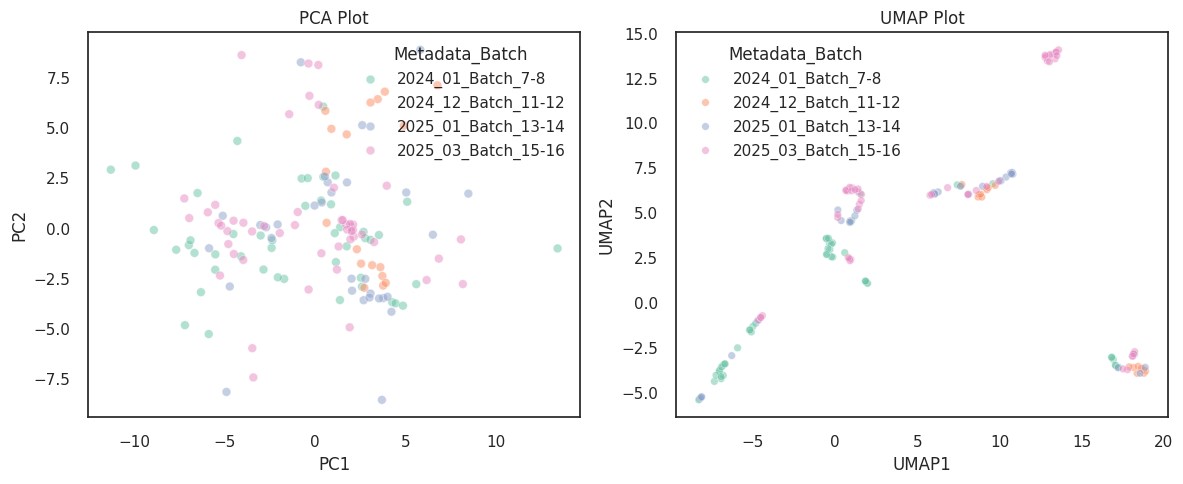

In [12]:
# Plot UMAP
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
sns.scatterplot(data=pca_df.sort_values(by="Metadata_Batch"), alpha=.5,
                x="PC1", y="PC2", hue="Metadata_Batch", palette="Set2", s=40, ax=axes[0]) ## hue=variant_type, 
# texts = []
# for i, label in enumerate(group2_labels):
#     if label in misloc_binary.filter(pl.col("mislocalized_both_batches"))["allele_0"]:
#         texts.append(ax.text(umap_result[i, 0], umap_result[i, 1], label, 
#                      fontsize=6, fontweight='bold', color='black'))
# adjust_text(texts, expand_points=(2, 2), arrowprops=dict(arrowstyle='-', color='red', lw=0.5), ax=ax) ## 
axes[0].set_title("PCA Plot")
axes[0].set_xlabel("PC1")
axes[0].set_ylabel("PC2")
axes[0].legend(title="Metadata_Batch")

# umap_df["Metadata_variant_type"] = well_profiles_plate_agg["Metadata_variant_type"].to_numpy()
# umap_df["Metadata_control_type"] = well_profiles_plate_agg["Metadata_control_type"].to_numpy()

# Plot UMAP
sns.scatterplot(data=umap_df.sort_values(by="Metadata_Batch"), x="UMAP1", y="UMAP2", hue="Metadata_Batch", palette="Set2", alpha=.5, s=30, ax=axes[1]) ## hue=variant_type, 
# texts = []
# for i, label in enumerate(group2_labels):
#     if label in misloc_binary.filter(pl.col("mislocalized_both_batches"))["allele_0"]:
#         texts.append(ax.text(umap_result[i, 0], umap_result[i, 1], label, 
#                      fontsize=6, fontweight='bold', color='black'))
# adjust_text(texts, expand_points=(2, 2), arrowprops=dict(arrowstyle='-', color='red', lw=0.5), ax=ax) ## 
axes[1].set_title("UMAP Plot")
axes[1].set_xlabel("UMAP1")
axes[1].set_ylabel("UMAP2")
axes[1].legend(title="Metadata_Batch")
plt.tight_layout()
plt.show()

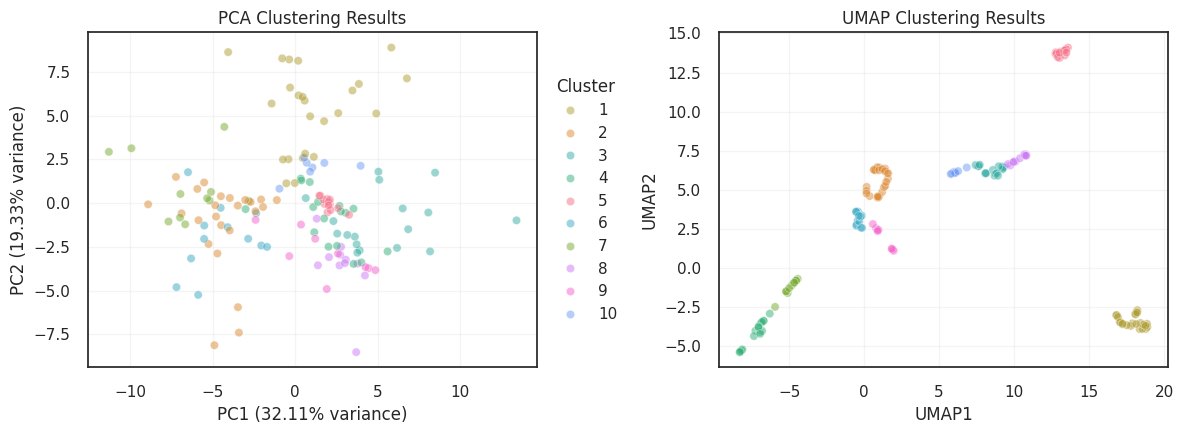

In [13]:
# Get unique clusters and create color palette
n_clusters = len(np.unique(dr_res_df["Metadata_cluster"]))
colors = sns.color_palette("husl", n_clusters)
color_map = {cluster: colors[i] for i, cluster in enumerate(dr_res_df["Metadata_cluster"].unique())}
auroc_thres = 0.95

fig, ax = plt.subplots(1,2, figsize=(12, 4.5))
# PCA plot
sns.scatterplot(
    dr_res_df,
    x="PC1",
    y="PC2",
    hue="Metadata_cluster",
    palette=color_map,
    ax=ax[0],
    alpha=.5,
    # legend=False
)
# for cluster in unique_clusters:
#     mask = np.array(clusters) == cluster
#     ax[0].scatter(data_pca[mask, 0], data_pca[mask, 1], 
#                  c=[color_map[cluster]], label=f'Cluster {cluster}',
#                  s=40, alpha=0.5)
ax[0].set_xlabel(f'PC1 ({pca.explained_variance_ratio_[0]:.2%} variance)')
ax[0].set_ylabel(f'PC2 ({pca.explained_variance_ratio_[1]:.2%} variance)')
ax[0].set_title('PCA Clustering Results')
ax[0].legend(bbox_to_anchor=(1.01, 0.5), loc='center left', title="Cluster", ncol=1)

# PCA plot
sns.scatterplot(
    dr_res_df,
    x="UMAP1",
    y="UMAP2",
    hue="Metadata_cluster",
    palette=color_map,
    ax=ax[1],
    alpha=.5,
    legend=False
)
# Add text labels for high-scoring points in PCA
high_score_mask = dr_res_df['Metadata_Altered_95th_perc_both_batches_GFP_ADJ']==True

# ax[1].get_legend().remove()

texts_pca = []
# for idx in dr_res_df[high_score_mask].index:
#    texts_pca.append(
#       ax[0].text(
#        dr_res_df.loc[idx, 'PC1'],
#        dr_res_df.loc[idx, 'PC2'],
#        str(idx),
#        fontsize=8
#    ))
# adjust_text(texts_pca, ax=ax[0], arrowprops=dict(arrowstyle='->', color='black', lw=0.5))

# Add text labels for high-scoring points in UMAP
texts_umap = []
# for idx in dr_res_df[high_score_mask].index:
#    texts_umap.append(ax[1].text(
#        dr_res_df.loc[idx, 'UMAP1'],
#        dr_res_df.loc[idx, 'UMAP2'],
#        str(idx),
#        fontsize=8
#    ))
# adjust_text(texts_umap, ax=ax[1], arrowprops=dict(arrowstyle='->', color='black', lw=0.5))

# for cluster in unique_clusters:
#     mask = np.array(clusters) == cluster
#     ax[1].scatter(embedding[mask, 0], embedding[mask, 1],
#                  c=[color_map[cluster]], label=f'Cluster {cluster}',
#                  s=40, alpha=0.5)

ax[1].set_xlabel('UMAP1')
ax[1].set_ylabel('UMAP2')
ax[1].set_title('UMAP Clustering Results')

ax[0].grid(alpha=.2)
ax[1].grid(alpha=.2)
plt.subplots_adjust(wspace=.3)
plt.tight_layout()
plt.show()

In [14]:
# Get cluster order from UMAP clustering
cluster_order = dr_res_df.sort_values('Metadata_cluster')['Metadata_cluster'].unique()

# Create cluster color mapping
n_clusters = len(np.unique(dr_res_df["Metadata_cluster"]))
cluster_colors = sns.color_palette("husl", n_clusters)
cluster_color_map = {cluster: cluster_colors[i] for i, cluster in enumerate(dr_res_df["Metadata_cluster"].unique())}

# Create ordered list based on clusters, then by score within clusters
ordered_variants = []
cluster_labels = []

for cluster in cluster_order:
#    print(cluster)
   cluster_variants = dr_res_df[dr_res_df['Metadata_cluster']==cluster].sort_values('Metadata_AUROC_Mean_GFP_ADJ', ascending=False).index.tolist()
   ordered_variants.extend(cluster_variants)
#    print(len(ordered_variants))
   cluster_labels.extend([cluster] * len(cluster_variants))

available_variants = []
available_cluster_labels = []
for i, variant in enumerate(ordered_variants):
   if variant in dr_res_df.sort_values('Metadata_AUROC_Mean_GFP_ADJ').index:
       available_variants.append(variant)
       available_cluster_labels.append(cluster_labels[i])

## Combine both color arrays as separate columns
row_colors_df = pd.DataFrame(index=ordered_variants)
row_colors_df['Cluster'] = [cluster_color_map[cluster] for cluster in available_cluster_labels]
# row_colors_df['AUROC_GFP'] = list(auroc_colors)

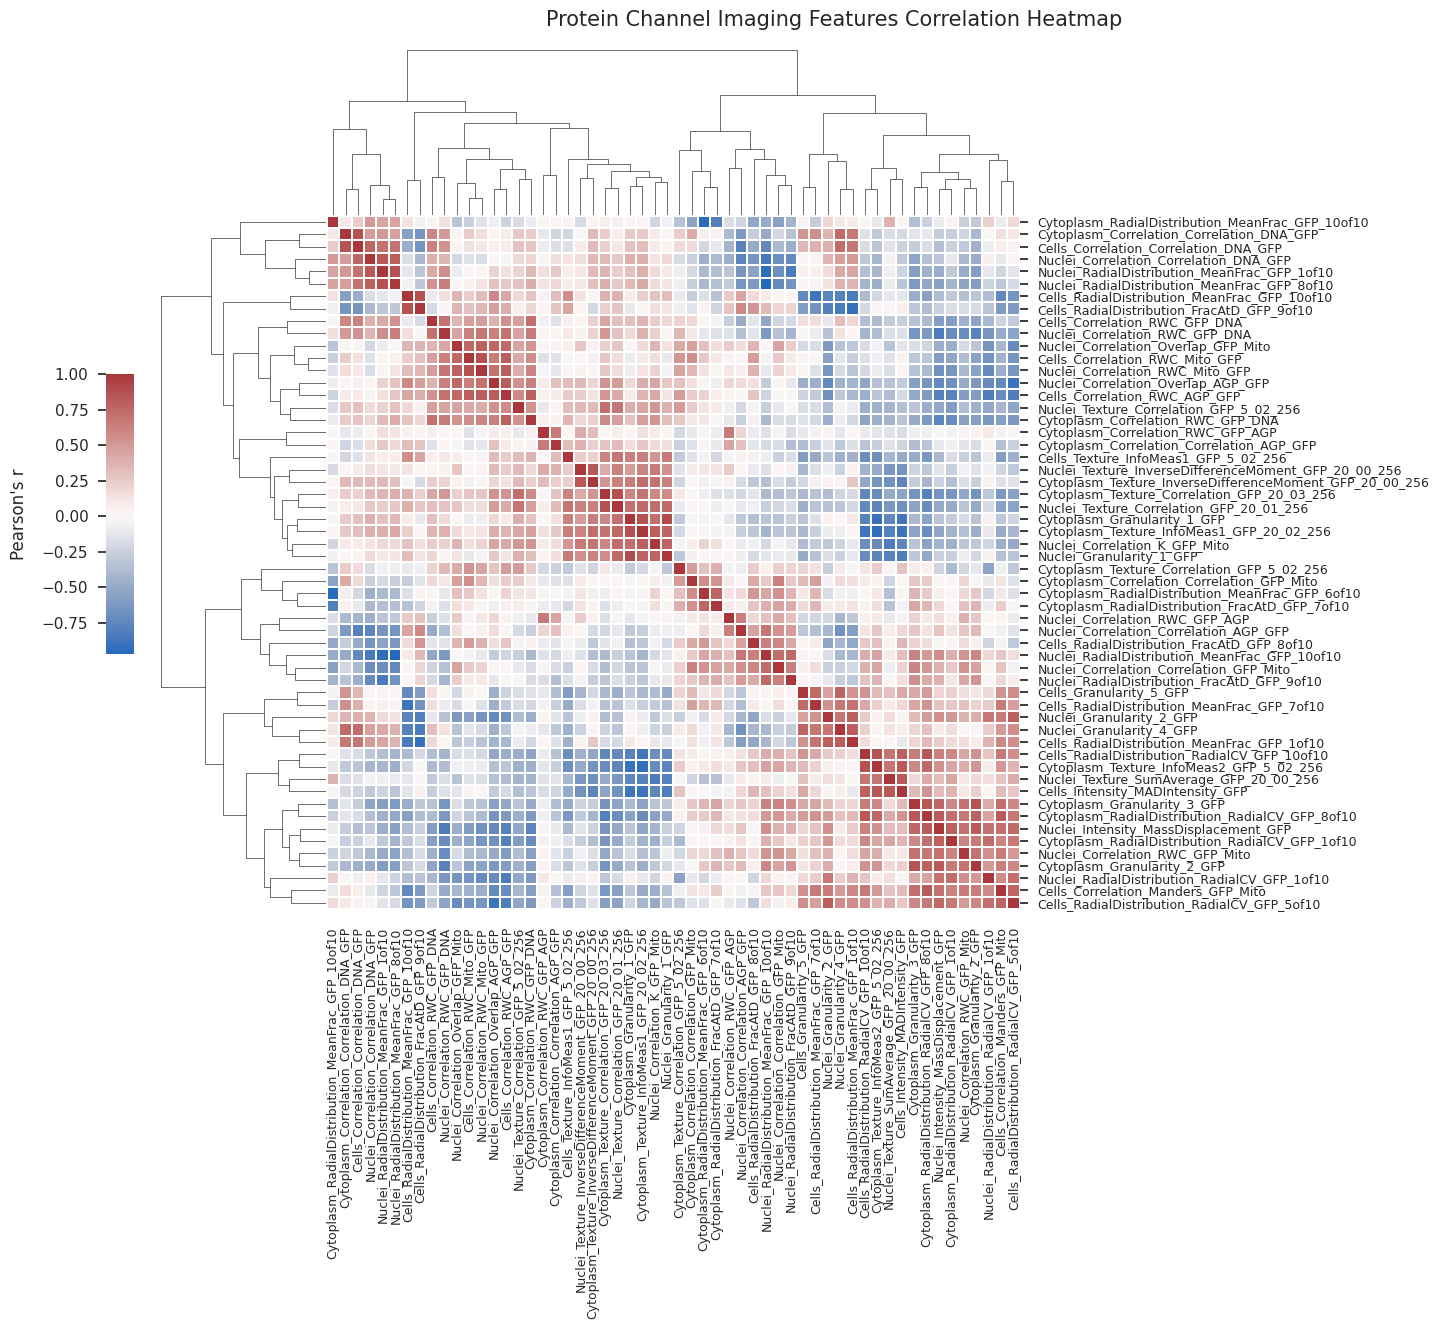

In [21]:
corr_df = df.loc[[idx for idx in row_colors_df.index if idx in misloc_alleles],:].corr()
g = sns.clustermap(
    data=corr_df,
    cmap="vlag",
    cbar_pos=(-.02, 0.55, 0.02, 0.2),
    yticklabels=1, xticklabels=1,
    square=True,
    figsize=(14,14),
    # annot=True, fmt=".2f",
    linewidth=.05, 
    # ax=ax
)
g.fig.suptitle("Protein Channel Imaging Features Correlation Heatmap", fontsize=15, y=1.01)
g.cax.yaxis.set_label_position('left')
g.cax.yaxis.set_ticks_position('left')
g.cax.set_ylabel(r"Pearson's r", labelpad=10) ##pearman's $\rho$
g.ax_heatmap.set_xticklabels(g.ax_heatmap.get_xticklabels(), fontsize=9)
g.ax_heatmap.set_yticklabels(g.ax_heatmap.get_yticklabels(), fontsize=9)
plt.show()

col_order = list(corr_df.columns[g.dendrogram_col.reordered_ind])

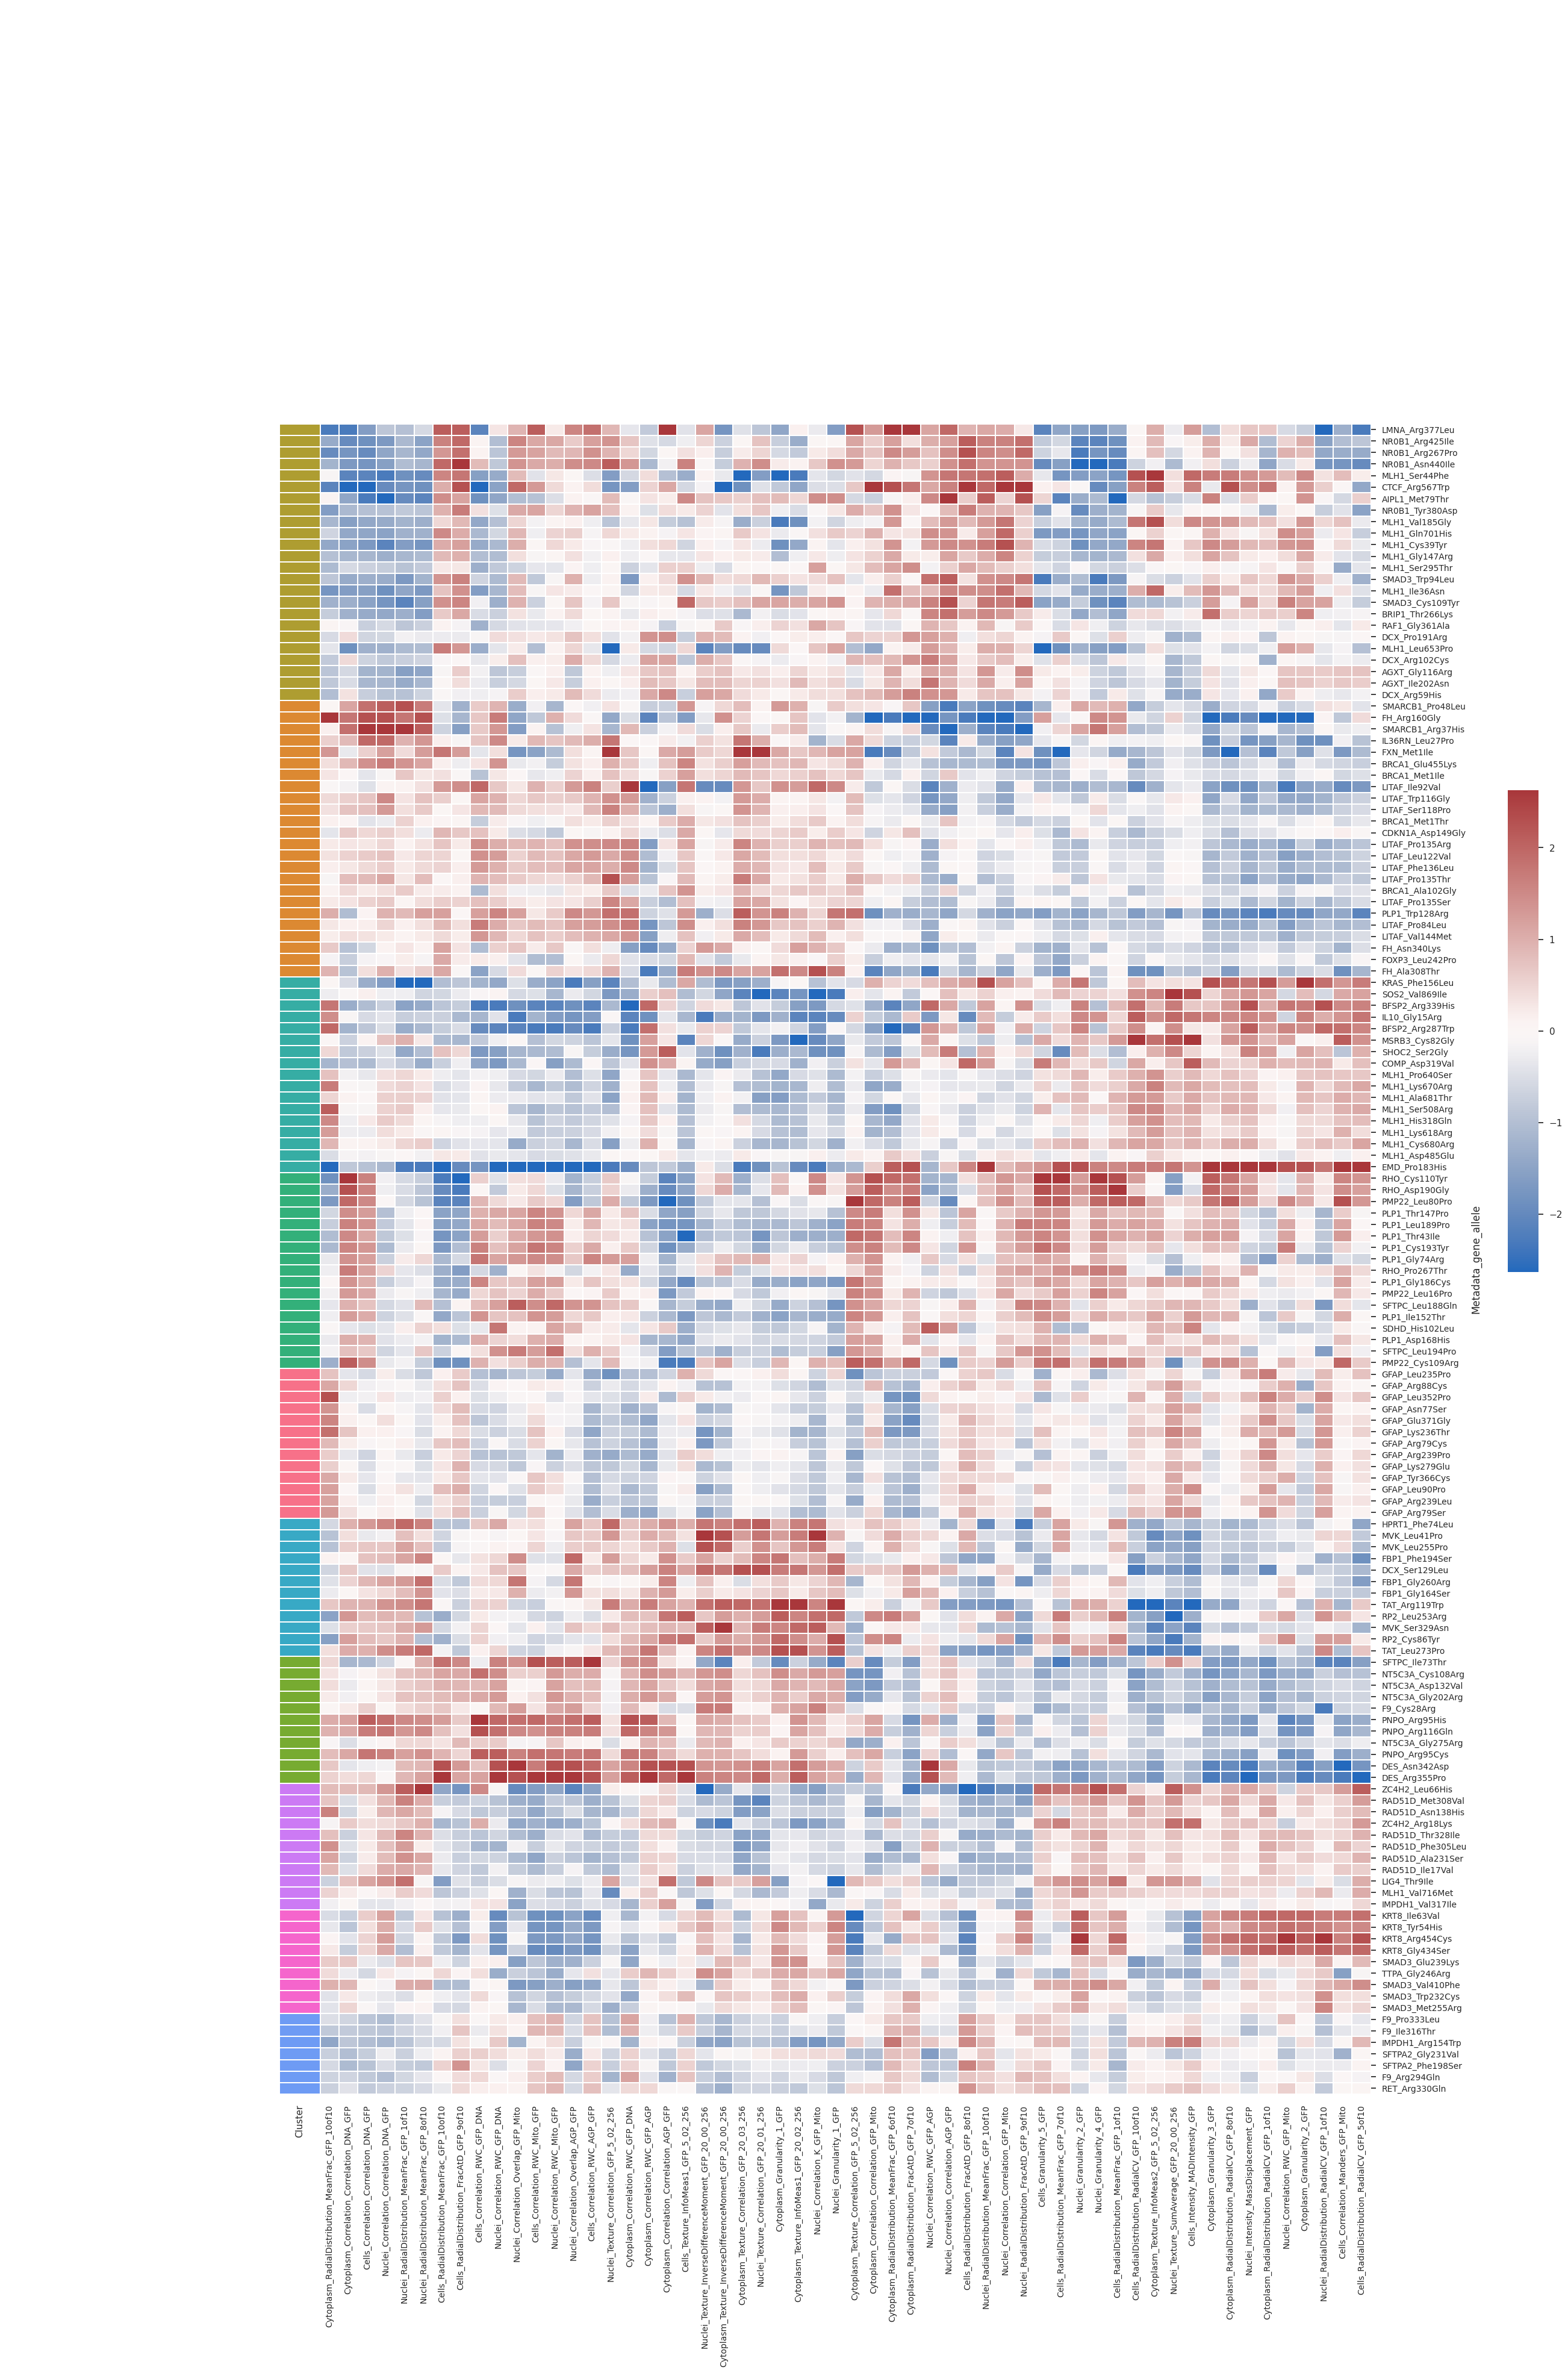

In [41]:
g = sns.clustermap(
    data=df.loc[[idx for idx in row_colors_df.index if idx in misloc_alleles],col_order],
    cmap="vlag",
    center=0,
    row_colors=row_colors_df.loc[[idx for idx in row_colors_df.index if idx in misloc_alleles],:],
    row_cluster=False,
    col_cluster=False,
    cbar_pos=(1.005, 0.47, 0.02, 0.2),
    figsize=(25, 40),
    yticklabels=1, 
    linewidth=.05, 
    # xticklabels=1,
    # dendrogram_ratio=0
)
g.ax_heatmap.set_xticklabels(g.ax_heatmap.get_xticklabels(), fontsize=10)
g.ax_heatmap.set_yticklabels(g.ax_heatmap.get_yticklabels(), fontsize=10)
plt.show()

In [23]:
dr_res_df.to_csv("../../3_outputs/variant_clustering_results.csv")
corr_df.loc[col_order, col_order].to_csv("protein_features_corr_mat.csv")
df.loc[[idx for idx in row_colors_df.index if idx in misloc_alleles],col_order].to_csv("../../3_outputs/variant_protein_feature_matrix.csv")